In [11]:
# ============================================================
# SETUP: YOLOv8 + Fine-tuned PARSeq OCR + Tesseract
# Google Colab — GPU compatible
# ============================================================

# 1. Install all Python dependencies
%pip install -q ultralytics pytesseract opencv-python-headless \
    pytorch-lightning lmdb timm einops pillow numpy matplotlib

# 2. Install Tesseract OCR system package
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr

# 3. Verify installations
import torch
import cv2
import lmdb
import pytesseract
import pytorch_lightning as pl
from ultralytics import YOLO
from PIL import Image
import timm
import einops
import matplotlib

print("=" * 55)
print("DEPENDENCY CHECK")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("OpenCV:", cv2.__version__)
print("PyTorch Lightning:", pl.__version__)
print("LMDB: installed")
print("Timm: installed")
print("Einops: installed")
print("Pillow: installed")
print("Matplotlib: installed")
print("Tesseract:", pytesseract.get_tesseract_version())
print("Ultralytics / YOLOv8: ready")

print("\nAll dependency checks completed.")
print("Next: run your PARSeq model-loading cell.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 7.1 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
DEPENDENCY CHECK
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
OpenCV: 4.14.0
PyTorch Lightning: 2.6.6
LMDB: installed
Timm: installed
Einops: installed
Pillow: installed
Matplotlib: installed
Tesseract: 5.3.4
Ultralytics / YOLOv8: ready

All dependency checks completed.
Next: run your PARSeq model-loading cell.


**Project Overview**

In [ ]:
# UFPR-ALPR: License Plate Detection and Recognition
# Cell 1: Project Setup and Dataset Verification
import os
import shutil
from google.colab import drive

# Ensure clean mount points to avoid 'Mountpoint must not already contain files' errors
try:
    print("Attempting to unmount any stale drive instances...")
    drive.flush_and_unmount()
except Exception:
    pass

if os.path.exists('/content/drive'):
    try:
        print("Cleaning up existing stale mount directories...")
        # If it is a directory but not fully mounted, remove it to clear the namespace
        shutil.rmtree('/content/drive')
    except Exception as e:
        print(f"Could not remove directory, will proceed with force remount: {e}")

# Safely mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

# Define project paths
DATASET_PATH = "/content/drive/MyDrive/UFPR-ALPR dataset"
MODEL_DIR = "/content/drive/MyDrive/UFPR_ALPR_Project/models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Verify dataset availability
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATASET_PATH}'. Please verify the Google Drive path."
    )

# Display professional summary
print("=" * 55)
print("   UFPR-ALPR DATASET ANALYSIS")
print("=" * 55)
print("Project       : License Plate Detection and Recognition")
print("Dataset       : UFPR-ALPR")
print("Status        : Available")
print("Image Format  : PNG")
print("Annotation    : TXT")
print("-" * 55)
print("Dataset Structure:")

for item in sorted(os.listdir(DATASET_PATH)):
    item_path = os.path.join(DATASET_PATH, item)
    if os.path.isdir(item_path):
        print(f"  [Folder] {item}/")
    else:
        print(f"  [File]   {item}")

print("-" * 55)
print("Model Backup  : Configured")
print("Setup Status  : Successful")
print("=" * 55)

Attempting to unmount any stale drive instances...
Drive not mounted, so nothing to flush and unmount.
Mounting Google Drive...
Mounted at /content/drive
   UFPR-ALPR DATASET ANALYSIS
Project       : License Plate Detection and Recognition
Dataset       : UFPR-ALPR
Status        : Available
Image Format  : PNG
Annotation    : TXT
-------------------------------------------------------
Dataset Structure:
  [File]   README.txt
  [Folder] testing/
  [Folder] training/
  [Folder] validation/
-------------------------------------------------------
Model Backup  : Configured
Setup Status  : Successful


In [ ]:

import os
import glob
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

PROJECT_DIR = "/content/drive/MyDrive/UFPR_ALPR_Project"
SOURCE_DIR = "/content/drive/MyDrive/UFPR-ALPR dataset"
DATA_DIR = os.path.join(PROJECT_DIR, "yolo_dataset")

CHARS = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
CHAR_TO_ID = {c: i + 1 for i, c in enumerate(CHARS)}

IMG_HEIGHT, IMG_WIDTH = 32, 128
BATCH_SIZE = 32

# Index the original UFPR annotation files.
annotation_index = {}

for split_name in ["training", "validation", "testing"]:
    folder = os.path.join(SOURCE_DIR, split_name)
    for path in glob.glob(
        os.path.join(folder, "**", "*.txt"),
        recursive=True
    ):
        stem = os.path.splitext(os.path.basename(path))[0]
        annotation_index[stem] = path

def read_plate_text(annotation_path):
    with open(annotation_path, "r", encoding="utf-8") as file:
        for line in file:
            if line.strip().lower().startswith("plate:"):
                raw = line.split(":", 1)[1].strip().upper()
                return "".join(c for c in raw if c in CHAR_TO_ID)
    return ""

def find_annotation(image_path):
    stem = os.path.splitext(os.path.basename(image_path))[0]
    original_stem = stem.split("__", 1)[-1]
    return annotation_index.get(original_stem)

class PlateOCRDataset(Dataset):
    def __init__(self, split):
        self.samples = []
        image_dir = os.path.join(DATA_DIR, "images", split)
        label_dir = os.path.join(DATA_DIR, "labels", split)

        paths = []
        for ext in ("*.png", "*.jpg", "*.jpeg"):
            paths.extend(glob.glob(os.path.join(image_dir, ext)))

        for image_path in paths:
            stem = os.path.splitext(os.path.basename(image_path))[0]
            label_path = os.path.join(label_dir, stem + ".txt")
            annotation_path = find_annotation(image_path)

            if not annotation_path or not os.path.isfile(label_path):
                continue

            text = read_plate_text(annotation_path)
            if len(text) != 7:
                continue

            with open(label_path, "r", encoding="utf-8") as file:
                rows = [
                    line.split()
                    for line in file
                    if line.strip()
                ]

            if not rows or len(rows[0]) < 5:
                continue

            _, xc, yc, bw, bh = map(float, rows[0][:5])
            self.samples.append(
                (image_path, text, (xc, yc, bw, bh))
            )

        print(f"{split}: {len(self.samples)} samples")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, text, box = self.samples[index]
        image = cv2.imread(image_path)

        if image is None:
            raise RuntimeError(f"Cannot read image: {image_path}")

        h, w = image.shape[:2]
        xc, yc, bw, bh = box

        x1 = max(0, int((xc - bw / 2) * w))
        y1 = max(0, int((yc - bh / 2) * h))
        x2 = min(w, int((xc + bw / 2) * w))
        y2 = min(h, int((yc + bh / 2) * h))

        crop = image[y1:y2, x1:x2]
        if crop.size == 0:
            raise RuntimeError(f"Empty plate crop: {image_path}")

        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        crop = cv2.resize(
            crop, (IMG_WIDTH, IMG_HEIGHT),
            interpolation=cv2.INTER_AREA
        )

        tensor = torch.from_numpy(crop).permute(2, 0, 1).float() / 255.0
        target = torch.tensor(
            [CHAR_TO_ID[c] for c in text],
            dtype=torch.long
        )

        return tensor, target, text

train_ds = PlateOCRDataset("train")
val_ds = PlateOCRDataset("val")
test_ds = PlateOCRDataset("test")

if not all([len(train_ds), len(val_ds), len(test_ds)]):
    raise RuntimeError(
        "A dataset split is empty. Check image paths, annotation names, "
        "and the prepared YOLO dataset."
    )

def collate_batch(batch):
    images, targets, texts = zip(*batch)
    return torch.stack(images), targets, list(texts)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, collate_fn=collate_batch
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, collate_fn=collate_batch
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, collate_fn=collate_batch
)

print("\nOCR dataset preparation complete.")
print("Training:", len(train_ds))
print("Validation:", len(val_ds))
print("Testing:", len(test_ds))


train: 1800 samples
val: 900 samples
test: 1800 samples

OCR dataset preparation complete.
Training: 1800
Validation: 900
Testing: 1800


In [ ]:

# Cell 2: Verify PARSeq and inspect OCR labels before fine-tuning

import torch

if "parseq" not in globals() or "parseq_transform" not in globals():
    raise RuntimeError(
        "PARSeq is not loaded. Run the PARSeq loading cell first."
    )

device = next(parseq.parameters()).device

print("PARSeq device:", device)
print("Model image size:", parseq.hparams.img_size)
print("Maximum label length:", parseq.hparams.max_label_length)

# Inspect actual plate labels from each split
for split_name, dataset in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds),
]:
    print(f"\n{split_name} examples:")
    for i in range(min(5, len(dataset))):
        _, _, plate_text = dataset[i]
        print(" ", plate_text)

# Inspect tokenizer decoding on a sample crop
image_tensor, _, actual_text = train_ds[0]
image_path = train_ds.samples[0][0]

import cv2
from PIL import Image
from IPython.display import display

image = cv2.imread(image_path)
_, _, (xc, yc, bw, bh) = train_ds.samples[0]
h, w = image.shape[:2]

x1 = max(0, int((xc - bw / 2) * w))
y1 = max(0, int((yc - bh / 2) * h))
x2 = min(w, int((xc + bw / 2) * w))
y2 = min(h, int((yc + bh / 2) * h))

crop = cv2.cvtColor(image[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

print("\nGround-truth plate:", actual_text)
display(Image.fromarray(crop))

print("\nInspection complete. No training has started.")


PARSeq device: cuda:0
Model image size: [32, 128]
Maximum label length: 25

Train examples:
  AOM8734
  AZC3032
  BBS8811
  AZJ4514
  FGD3938

Validation examples:
  AAJ5801
  GZM8901
  GZM8901
  MHB6459
  AOT0264

Test examples:
  AKT8174
  ASU1099
  BCJ9595
  AUG0936
  BAS8216

Ground-truth plate: AOM8734



Inspection complete. No training has started.


In [ ]:

# Cell 3: Fine-tune pretrained PARSeq on UFPR-ALPR

import os
import time
import json
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

# ---------- Configuration ----------
PARSEQ_DIR = os.path.join(PROJECT_DIR, "parseq_ocr")
os.makedirs(PARSEQ_DIR, exist_ok=True)

PARSEQ_BEST_PATH = os.path.join(
    PARSEQ_DIR, "parseq_ufpr_best.pt"
)
PARSEQ_REPORT_PATH = os.path.join(
    PARSEQ_DIR, "parseq_training_report.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EPOCHS = 5
BATCH_SIZE = 16
LEARNING_RATE = 1e-5

if "parseq" not in globals() or "parseq_transform" not in globals():
    raise RuntimeError(
        "Run the PARSeq loading cell before this cell."
    )

# ---------- Apply PARSeq's official image transform ----------
class PARSeqDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image_path, text, box = self.base_dataset.samples[index]

        image = cv2.imread(image_path)
        if image is None:
            raise RuntimeError(f"Cannot read image: {image_path}")

        h, w = image.shape[:2]
        xc, yc, bw, bh = box

        x1 = max(0, int((xc - bw / 2) * w))
        y1 = max(0, int((yc - bh / 2) * h))
        x2 = min(w, int((xc + bw / 2) * w))
        y2 = min(h, int((yc + bh / 2) * h))

        crop = image[y1:y2, x1:x2]
        if crop.size == 0:
            raise RuntimeError(f"Empty plate crop: {image_path}")

        crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        pil_image = Image.fromarray(crop)

        # Use the preprocessing expected by pretrained PARSeq
        tensor = parseq_transform(pil_image)
        return tensor, text

def parseq_collate(batch):
    images, labels = zip(*batch)
    return torch.stack(images), list(labels)

parseq_train_ds = PARSeqDataset(train_ds)
parseq_val_ds = PARSeqDataset(val_ds)

parseq_train_loader = DataLoader(
    parseq_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda"),
    collate_fn=parseq_collate
)

parseq_val_loader = DataLoader(
    parseq_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda"),
    collate_fn=parseq_collate
)

# Verify the installed PARSeq API before starting training
if not callable(getattr(parseq, "forward_logits_loss", None)):
    raise RuntimeError(
        "This PARSeq object does not expose forward_logits_loss. "
        "Training was not started. Send me this error."
    )

parseq = parseq.to(DEVICE)
optimizer = torch.optim.AdamW(
    parseq.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

def run_parseq_epoch(loader, training):
    parseq.train(training)
    total_loss = 0.0
    total_samples = 0
    exact_matches = 0

    progress = tqdm(loader, leave=False)

    for images, labels in progress:
        images = images.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits, loss, loss_numel = parseq.forward_logits_loss(
                images, labels
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    parseq.parameters(), max_norm=5.0
                )
                optimizer.step()

        batch_size = len(labels)
        total_loss += float(loss.detach()) * batch_size
        total_samples += batch_size

        predictions, _ = parseq.tokenizer.decode(
            logits.detach().softmax(-1)
        )
        exact_matches += sum(
            pred == actual
            for pred, actual in zip(predictions, labels)
        )

        progress.set_postfix(loss=f"{float(loss.detach()):.4f}")

    return (
        total_loss / max(total_samples, 1),
        exact_matches / max(total_samples, 1)
    )

# ---------- Fine-tuning ----------
best_val_loss = float("inf")
history = []
start_time = time.time()

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Training samples:", len(parseq_train_ds))
print("Validation samples:", len(parseq_val_ds))
print("Epochs:", EPOCHS)
print("Best checkpoint:", PARSEQ_BEST_PATH)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_parseq_epoch(
        parseq_train_loader, training=True
    )
    val_loss, val_acc = run_parseq_epoch(
        parseq_val_loader, training=False
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_exact_match_accuracy": train_acc,
        "val_loss": val_loss,
        "val_exact_match_accuracy": val_acc
    }
    history.append(row)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train exact match={train_acc:.2%} | "
        f"val loss={val_loss:.4f} | "
        f"val exact match={val_acc:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict": parseq.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "val_exact_match_accuracy": val_acc,
                "model_name": "PARSeq fine-tuned on UFPR-ALPR"
            },
            PARSEQ_BEST_PATH
        )
        print("Saved new best checkpoint.")

# Restore the best validation checkpoint
checkpoint = torch.load(
    PARSEQ_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)
parseq.load_state_dict(checkpoint["model_state_dict"])
parseq.eval()

report = {
    "model": "PARSeq fine-tuned on UFPR-ALPR",
    "epochs_completed": len(history),
    "train_samples": len(parseq_train_ds),
    "validation_samples": len(parseq_val_ds),
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["val_loss"]),
    "best_validation_exact_match_accuracy": float(
        checkpoint["val_exact_match_accuracy"]
    ),
    "training_seconds": float(time.time() - start_time),
    "checkpoint": PARSEQ_BEST_PATH,
    "history": history
}

with open(PARSEQ_REPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\nFine-tuning complete.")
print("Best epoch:", report["best_epoch"])
print(
    "Best validation exact match:",
    f"{report['best_validation_exact_match_accuracy']:.2%}"
)
print("Checkpoint:", PARSEQ_BEST_PATH)
print("Report:", PARSEQ_REPORT_PATH)


Device: cuda
GPU: Tesla T4
Training samples: 1800
Validation samples: 900
Epochs: 5
Best checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_ufpr_best.pt


  0%|          | 0/113 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1/5 | train loss=2.5106 | train exact match=29.00% | val loss=1.2581 | val exact match=62.89%
Saved new best checkpoint.


  0%|          | 0/113 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

... (7 outputs left out)

Epoch 4/5 | train loss=0.2995 | train exact match=80.33% | val loss=0.5758 | val exact match=74.56%
Saved new best checkpoint.


  0%|          | 0/113 [00:00<?, ?it/s]

  0%|          | 0/57 [00:00<?, ?it/s]

Epoch 5/5 | train loss=0.2028 | train exact match=84.67% | val loss=0.5369 | val exact match=75.78%
Saved new best checkpoint.

Fine-tuning complete.
Best epoch: 5
Best validation exact match: 75.78%
Checkpoint: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_ufpr_best.pt
Report: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_training_report.json


In [ ]:

# Cell 4: Final held-out test evaluation for fine-tuned PARSeq

import os
import json
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

PARSEQ_BEST_PATH = (
    "/content/drive/MyDrive/UFPR_ALPR_Project/"
    "parseq_ocr/parseq_ufpr_best.pt"
)

PARSEQ_REPORT_PATH = (
    "/content/drive/MyDrive/UFPR_ALPR_Project/"
    "parseq_ocr/parseq_test_evaluation.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if not os.path.isfile(PARSEQ_BEST_PATH):
    raise FileNotFoundError(
        f"Saved checkpoint not found: {PARSEQ_BEST_PATH}"
    )

# Load the best validation checkpoint
checkpoint = torch.load(
    PARSEQ_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

parseq.load_state_dict(checkpoint["model_state_dict"])
parseq = parseq.to(DEVICE).eval()

# Use single-process data loading to avoid the previous
# notebook multiprocessing cleanup warnings.
parseq_test_ds = PARSeqDataset(test_ds)

parseq_test_loader = DataLoader(
    parseq_test_ds,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    collate_fn=parseq_collate
)

exact_correct = 0
total_samples = 0
char_correct = 0
char_total = 0
mismatch_examples = []

with torch.inference_mode():
    for images, labels in tqdm(parseq_test_loader):
        images = images.to(DEVICE)

        logits = parseq(images)
        decoded, _ = parseq.tokenizer.decode(logits.softmax(-1))

        for predicted, actual in zip(decoded, labels):
            predicted = str(predicted).strip().upper()
            actual = str(actual).strip().upper()

            total_samples += 1

            if predicted == actual:
                exact_correct += 1

            # Levenshtein edit distance gives a better
            # character-level metric than position-only matching.
            previous = list(range(len(actual) + 1))

            for i, pred_char in enumerate(predicted, start=1):
                current = [i]
                for j, true_char in enumerate(actual, start=1):
                    cost = 0 if pred_char == true_char else 1
                    current.append(
                        min(
                            current[-1] + 1,
                            previous[j] + 1,
                            previous[j - 1] + cost
                        )
                    )
                previous = current

            distance = previous[-1]
            char_correct += max(len(actual) - distance, 0)
            char_total += len(actual)

            if predicted != actual and len(mismatch_examples) < 25:
                mismatch_examples.append({
                    "actual": actual,
                    "predicted": predicted
                })

exact_accuracy = (
    exact_correct / total_samples if total_samples else 0.0
)
character_accuracy = (
    char_correct / char_total if char_total else 0.0
)

report = {
    "model": "PARSeq fine-tuned on UFPR-ALPR",
    "checkpoint": PARSEQ_BEST_PATH,
    "best_validation_epoch": int(checkpoint["epoch"]),
    "test_samples": total_samples,
    "exact_match_correct": exact_correct,
    "exact_match_accuracy": exact_accuracy,
    "character_accuracy_edit_distance": character_accuracy,
    "character_count": char_total,
    "mismatch_examples": mismatch_examples
}

with open(PARSEQ_REPORT_PATH, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n========== PARSEQ TEST RESULTS ==========")
print(f"Test samples:             {total_samples}")
print(f"Exact matches:            {exact_correct}")
print(f"Exact-match accuracy:     {exact_accuracy:.2%}")
print(f"Character accuracy:       {character_accuracy:.2%}")
print("\nExamples of incorrect predictions:")
for item in mismatch_examples[:10]:
    print(
        f"Actual: {item['actual']} | "
        f"Predicted: {item['predicted']}"
    )

print("\nSaved test report:", PARSEQ_REPORT_PATH)
print("Saved model:", PARSEQ_BEST_PATH)


  0%|          | 0/113 [00:00<?, ?it/s]


========== PARSEQ TEST RESULTS ==========
Test samples:             1800
Exact matches:            1377
Exact-match accuracy:     76.50%
Character accuracy:       93.16%

Examples of incorrect predictions:
Actual: AKT8174 | Predicted: AKT4174
Actual: AUG0936 | Predicted: AUG600
Actual: BAS8216 | Predicted: BAS88216
Actual: AWZ7648 | Predicted: AW764B
Actual: AIQ1056 | Predicted: AIQ1Q56
Actual: AEK0977 | Predicted: AEK77
Actual: ALJ9348 | Predicted: ALJ489
Actual: AWP0816 | Predicted: AMP0816
Actual: ASG9143 | Predicted: ASCAS
Actual: AEK0977 | Predicted: AEK

Saved test report: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_test_evaluation.json
Saved model: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_ufpr_best.pt


Image: track0091__track0091[01].png
Predicted plate: MLS5511
YOLO detection confidence: 0.8861

Detected plate crop:


Full image with prediction:


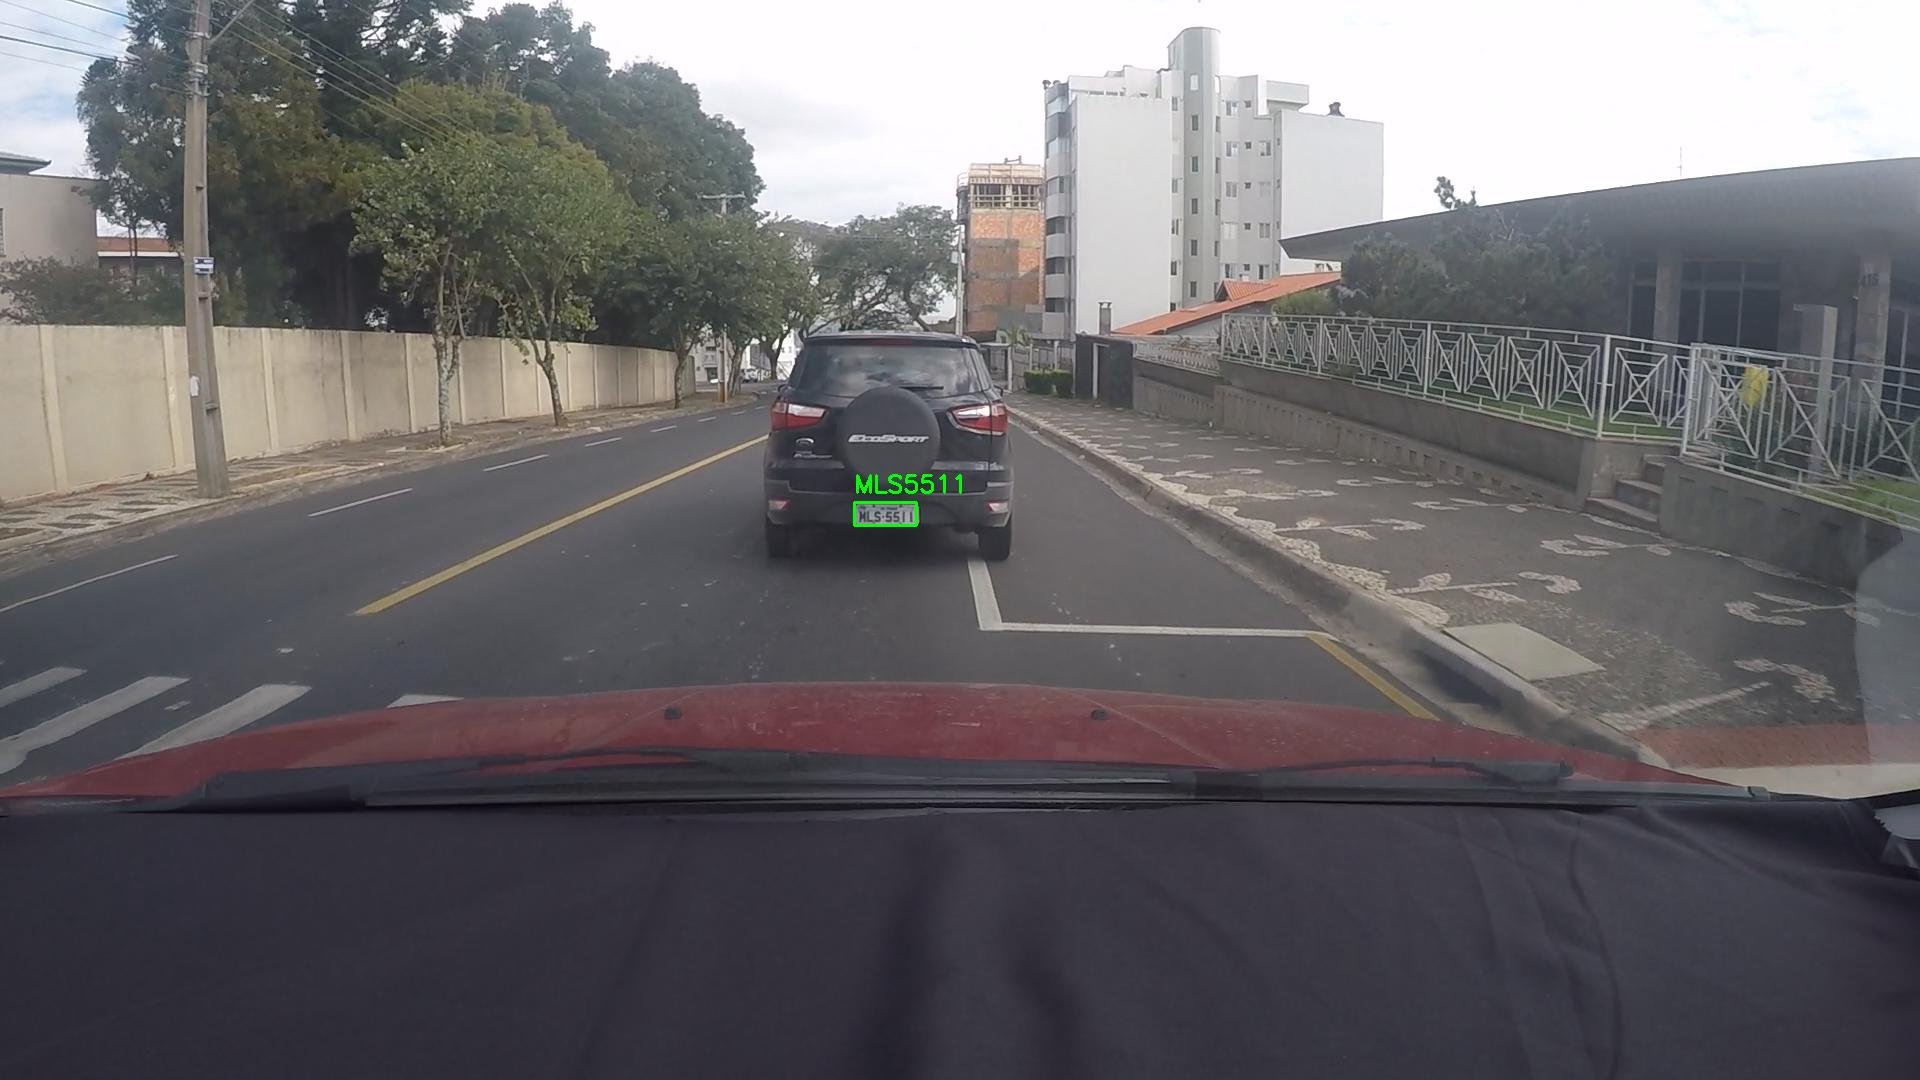

In [ ]:

# Cell 5: End-to-end license plate detection and recognition

import os
import glob
import cv2
import torch
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/UFPR_ALPR_Project"

YOLO_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "yolov8_plate_detect",
    "weights",
    "best.pt"
)

PARSEQ_BEST_PATH = os.path.join(
    PROJECT_DIR, "parseq_ocr", "parseq_ufpr_best.pt"
)

TEST_IMAGE_DIR = os.path.join(
    PROJECT_DIR, "yolo_dataset", "images", "test"
)

if not os.path.isfile(YOLO_MODEL_PATH):
    raise FileNotFoundError(f"YOLO model not found: {YOLO_MODEL_PATH}")

if not os.path.isfile(PARSEQ_BEST_PATH):
    raise FileNotFoundError(f"PARSeq model not found: {PARSEQ_BEST_PATH}")

# Load the existing detector and fine-tuned recognizer.
detector = YOLO(YOLO_MODEL_PATH)

checkpoint = torch.load(
    PARSEQ_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)
parseq.load_state_dict(checkpoint["model_state_dict"])
parseq = parseq.to(DEVICE).eval()

image_paths = []
for ext in ("*.png", "*.jpg", "*.jpeg"):
    image_paths.extend(glob.glob(os.path.join(TEST_IMAGE_DIR, ext)))

if not image_paths:
    raise FileNotFoundError(f"No test images found in {TEST_IMAGE_DIR}")

# Use one test image for this first demo.
image_path = sorted(image_paths)[0]
image = cv2.imread(image_path)

if image is None:
    raise RuntimeError(f"Cannot read image: {image_path}")

results = detector.predict(
    source=image,
    conf=0.25,
    verbose=False
)

print("Image:", os.path.basename(image_path))

if len(results[0].boxes) == 0:
    print("No license plate detected. Try another test image.")
else:
    boxes = results[0].boxes
    best_idx = int(boxes.conf.argmax().item())

    x1, y1, x2, y2 = boxes.xyxy[best_idx].int().cpu().tolist()

    h, w = image.shape[:2]
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        raise RuntimeError("Detected plate crop is empty.")

    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    plate_image = Image.fromarray(crop_rgb)

    input_tensor = parseq_transform(plate_image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = parseq(input_tensor)
        decoded, _ = parseq.tokenizer.decode(logits.softmax(-1))

    predicted_plate = str(decoded[0]).strip().upper()
    confidence = float(boxes.conf[best_idx].item())

    # Draw the detection and OCR result on the original image.
    annotated = image.copy()
    cv2.rectangle(
        annotated, (x1, y1), (x2, y2), (0, 255, 0), 2
    )
    cv2.putText(
        annotated,
        predicted_plate,
        (x1, max(25, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

    print("Predicted plate:", predicted_plate)
    print("YOLO detection confidence:", round(confidence, 4))
    print("\nDetected plate crop:")
    display(plate_image)
    print("Full image with prediction:")
    display(Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)))


###*Dataset Analysis*

In [ ]:

# CELL 2 — Dataset Analysis
# Reusable for object detection, classification, OCR, and other models

import os
from collections import Counter

# Original dataset directory (set DATASET_PATH in Cell 1)
if "DATASET_PATH" not in globals():
    DATASET_PATH = "/content/drive/MyDrive/UFPR-ALPR dataset"

MAX_FILES = 8000
MAX_DEPTH = 3
SAMPLE_LIMIT = 3

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset directory not found:\n{DATASET_PATH}"
    )

file_counts = Counter()
examples = {}
scanned = 0
limit_reached = False

for root, dirs, files in os.walk(DATASET_PATH):
    relative_root = os.path.relpath(root, DATASET_PATH)
    depth = 0 if relative_root == "." else relative_root.count(os.sep) + 1

    if depth >= MAX_DEPTH:
        dirs.clear()

    dirs[:] = sorted(d for d in dirs if not d.startswith("."))

    for name in sorted(files):
        if name.startswith("."):
            continue

        ext = os.path.splitext(name)[1].lower() or "[no extension]"
        file_counts[ext] += 1
        examples.setdefault(ext, [])

        if len(examples[ext]) < SAMPLE_LIMIT:
            examples[ext].append(
                os.path.relpath(os.path.join(root, name), DATASET_PATH)
            )

        scanned += 1

        if scanned >= MAX_FILES:
            limit_reached = True
            break

    if limit_reached:
        break

# Professional report
print("=" * 65)
print("                 DATASET ANALYSIS REPORT")
print("=" * 65)

print(f"Dataset location : {DATASET_PATH}")
print(f"Files inspected  : {scanned}")
print(f"File types found : {len(file_counts)}")
print(f"Scan status      : {'PARTIAL (file limit reached)' if limit_reached else 'COMPLETED'}")

print("\n" + "-" * 65)
print("1. FILE TYPE SUMMARY")
print("-" * 65)
print(f"{'Extension':<18}{'Count':>12}   {'Typical role'}")
print("-" * 65)

descriptions = {
    ".png": "Image data",
    ".jpg": "Image data",
    ".jpeg": "Image data",
    ".bmp": "Image data",
    ".txt": "Annotations or documentation",
    ".csv": "Tabular labels or metadata",
    ".json": "Structured annotations or metadata",
    ".xml": "Structured annotations (possibly Pascal VOC)",
    ".yaml": "Configuration (possibly YOLO)",
    ".yml": "Configuration",
    ".npy": "NumPy array",
    ".npz": "Compressed NumPy arrays",
    ".pt": "PyTorch model/checkpoint",
    ".pth": "PyTorch model/checkpoint",
}

for ext, count in file_counts.most_common():
    role = descriptions.get(ext, "Other / needs inspection")
    print(f"{ext:<18}{count:>12}   {role}")

print("\n" + "-" * 65)
print("2. SAMPLE FILES")
print("-" * 65)

for ext, names in examples.items():
    print(f"\n{ext}:")
    for name in names:
        print(f"  - {name}")

print("\n" + "-" * 65)
print("3. DATASET FORMAT INTERPRETATION")
print("-" * 65)

image_count = sum(
    count for ext, count in file_counts.items()
    if ext in {".png", ".jpg", ".jpeg", ".bmp"}
)

print(f"Image files inspected : {image_count}")

if ".txt" in file_counts:
    print(f"Text files inspected  : {file_counts['.txt']}")
    print(
        "Note: .txt files can contain original annotations, "
        "plain text, or YOLO labels. Extension alone does not "
        "identify the format."
    )

print("\nFormat guidance:")
print("- Original annotated images can be used by multiple model types.")
print("- Object detection needs bounding-box labels.")
print("- Image classification needs class labels.")
print("- OCR needs text transcriptions and suitable image/region labels.")
print("- YOLO training needs YOLO-compatible labels and a dataset YAML file.")
print("- Conversion or preprocessing may be required for each model.")

print("\n" + "=" * 65)
print("DATASET ANALYSIS FINISHED")
print("=" * 65)


                 DATASET ANALYSIS REPORT
Dataset location : /content/drive/MyDrive/UFPR-ALPR dataset
Files inspected  : 8000
File types found : 2
Scan status      : PARTIAL (file limit reached)

-----------------------------------------------------------------
1. FILE TYPE SUMMARY
-----------------------------------------------------------------
Extension                Count   Typical role
-----------------------------------------------------------------
.txt                      4000   Annotations or documentation
.png                      4000   Image data

-----------------------------------------------------------------
2. SAMPLE FILES
-----------------------------------------------------------------

.txt:
  - README.txt
  - testing/track0091/track0091[01].txt
  - testing/track0091/track0091[02].txt

.png:
  - testing/track0091/track0091[01].png
  - testing/track0091/track0091[02].png
  - testing/track0091/track0091[03].png

-------------------------------------------------------

###**Visualize diverse images and license plate annotations**

Distinct tracks sampled: 6


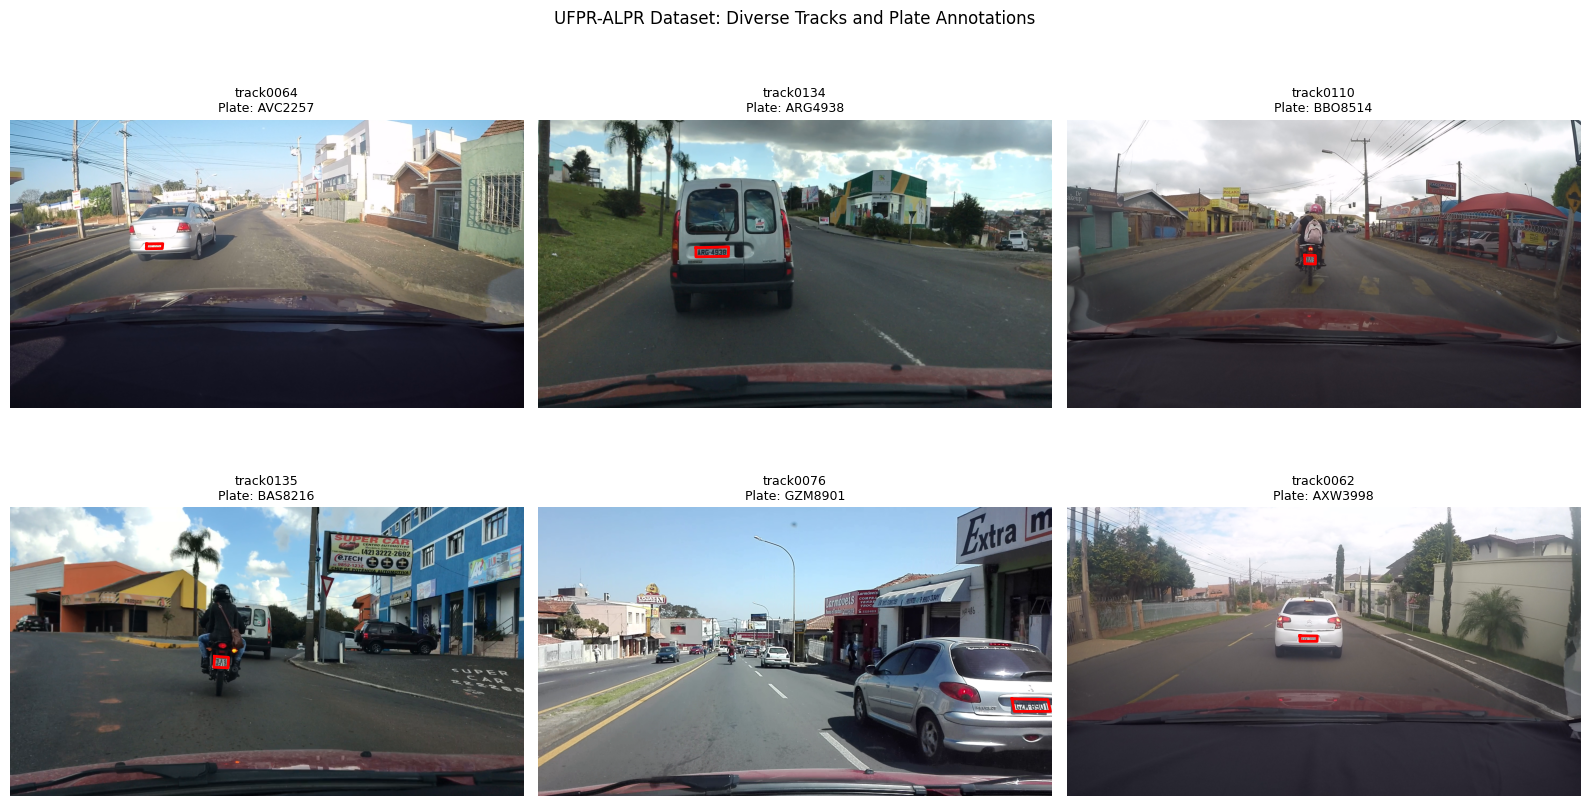

In [ ]:

# CELL 3 — Visualize diverse images and license plate annotations
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
IMAGE_EXTS = {".png", ".jpg", ".jpeg"}

# Find one image from each track folder
track_samples = {}

for split in ["training", "validation", "testing"]:
    split_path = os.path.join(DATASET_PATH, split)
    if not os.path.isdir(split_path):
        continue

    for track in sorted(os.listdir(split_path)):
        track_path = os.path.join(split_path, track)
        if not os.path.isdir(track_path):
            continue

        for name in sorted(os.listdir(track_path)):
            if os.path.splitext(name)[1].lower() in IMAGE_EXTS:
                track_samples[os.path.join(track_path, name)] = split
                break

# Select images from different tracks
candidates = list(track_samples.keys())
random.shuffle(candidates)
samples = candidates[:6]

print("Distinct tracks sampled:", len(samples))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, img_path in zip(axes, samples):
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)

    # Read matching annotation
    txt_path = os.path.splitext(img_path)[0] + ".txt"
    plate_text = "Unknown"

    if os.path.isfile(txt_path):
        with open(txt_path, "r", encoding="utf-8", errors="replace") as f:
            lines = f.readlines()

        for line in lines:
            if line.startswith("plate:"):
                plate_text = line.split(":", 1)[1].strip()

            elif line.startswith("corners:"):
                try:
                    coords = line.split(":", 1)[1].split()
                    points = [tuple(map(int, p.split(","))) for p in coords]
                    points.append(points[0])
                    xs, ys = zip(*points)
                    ax.plot(xs, ys, "r-", linewidth=2)
                except (ValueError, IndexError):
                    pass

    ax.set_title(
        f"{os.path.basename(os.path.dirname(img_path))}\n"
        f"Plate: {plate_text}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.suptitle("UFPR-ALPR Dataset: Diverse Tracks and Plate Annotations")
plt.tight_layout()
plt.show()


### 1. YOLO Label Generation & Dataset Configuration
We will now parse the dataset annotations and convert the four corner coordinates into normalized YOLO format coordinates (`x_center`, `y_center`, `width`, `height`). We will also generate the `dataset.yaml` file needed for Ultralytics YOLO training and save it directly to Google Drive.

In [ ]:

import os
import re
import yaml
import shutil
from PIL import Image

# 1. Set paths
DATASET_PATH = "/content/drive/MyDrive/UFPR-ALPR dataset"
YOLO_ROOT = "/content/yolo_dataset"
CONFIG_DIR = "/content/drive/MyDrive/UFPR_ALPR_Project/dataset_config"

# 2. Create a clean YOLO dataset structure
if os.path.exists(YOLO_ROOT):
    shutil.rmtree(YOLO_ROOT)

for split in ["train", "val", "test"]:
    os.makedirs(f"{YOLO_ROOT}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_ROOT}/labels/{split}", exist_ok=True)

os.makedirs(CONFIG_DIR, exist_ok=True)


# 3. Convert plate corner points to YOLO format
def convert_annotation(txt_path, img_width, img_height):
    with open(txt_path, "r", encoding="utf-8") as f:
        content = f.read()

    match = re.search(r"corners:\s*([^\r\n]+)", content)
    if not match:
        return None

    values = re.findall(r"-?\d+(?:\.\d+)?", match.group(1))
    if len(values) < 8:
        return None

    points = list(map(float, values[:8]))
    xs = points[0::2]
    ys = points[1::2]

    x_min = max(0, min(xs))
    y_min = max(0, min(ys))
    x_max = min(img_width, max(xs))
    y_max = min(img_height, max(ys))

    if x_max <= x_min or y_max <= y_min:
        return None

    x_center = ((x_min + x_max) / 2) / img_width
    y_center = ((y_min + y_max) / 2) / img_height
    width = (x_max - x_min) / img_width
    height = (y_max - y_min) / img_height

    return (
        f"0 {x_center:.6f} {y_center:.6f} "
        f"{width:.6f} {height:.6f}"
    )


# 4. Prepare images and labels using symbolic links
splits = {
    "training": "train",
    "validation": "val",
    "testing": "test"
}

counts = {"train": 0, "val": 0, "test": 0}
skipped = 0

for source_split, target_split in splits.items():
    source_root = os.path.join(DATASET_PATH, source_split)

    if not os.path.isdir(source_root):
        print("Missing folder:", source_root)
        continue

    print(f"Preparing {source_split}...", flush=True)

    for folder, _, filenames in os.walk(source_root):
        for filename in filenames:
            if not filename.lower().endswith(".png"):
                continue

            image_path = os.path.join(folder, filename)
            txt_path = os.path.splitext(image_path)[0] + ".txt"

            if not os.path.isfile(txt_path):
                skipped += 1
                continue

            try:
                with Image.open(image_path) as img:
                    img_width, img_height = img.size

                label = convert_annotation(
                    txt_path, img_width, img_height
                )

                if label is None:
                    skipped += 1
                    continue

                # Include track name to avoid filename collisions
                track = os.path.basename(folder)
                unique_name = f"{track}__{filename}"

                image_dest = os.path.join(
                    YOLO_ROOT, "images", target_split, unique_name
                )
                label_dest = os.path.join(
                    YOLO_ROOT, "labels", target_split,
                    os.path.splitext(unique_name)[0] + ".txt"
                )

                # Link image instead of copying its large contents
                os.symlink(os.path.abspath(image_path), image_dest)

                with open(label_dest, "w", encoding="utf-8") as f:
                    f.write(label + "\n")

                counts[target_split] += 1

            except Exception as error:
                skipped += 1
                print(f"Skipped {filename}: {error}", flush=True)

        # Progress indicator
        print(
            f"{target_split}: {counts[target_split]} images prepared",
            flush=True
        )


# 5. Save YOLO configuration
yaml_path = os.path.join(CONFIG_DIR, "dataset.yaml")

config = {
    "path": YOLO_ROOT,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "license_plate"}
}

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\n===== DATASET PREPARATION COMPLETE =====")
print("Training images:", counts["train"])
print("Validation images:", counts["val"])
print("Testing images:", counts["test"])
print("Skipped files:", skipped)
print("YOLO config:", yaml_path)


Preparing training...
train: 0 images prepared
train: 30 images prepared
train: 60 images prepared
train: 90 images prepared
train: 120 images prepared
train: 150 images prepared
train: 180 images prepared
train: 210 images prepared
train: 240 images prepared
train: 270 images prepared
train: 300 images prepared
train: 330 images prepared
train: 360 images prepared
train: 390 images prepared
train: 420 images prepared
train: 450 images prepared
train: 480 images prepared
train: 510 images prepared
train: 540 images prepared
train: 570 images prepared
train: 600 images prepared
train: 630 images prepared
train: 660 images prepared
train: 690 images prepared
train: 720 images prepared
train: 750 images prepared
train: 780 images prepared
train: 810 images prepared
train: 840 images prepared
train: 870 images prepared
train: 900 images prepared
train: 930 images prepared
train: 960 images prepared
train: 990 images prepared
train: 1020 images prepared
train: 1050 images prepared
train: 10

In [ ]:

# CELL 8: Save the prepared YOLO dataset permanently in Google Drive

import os
import shutil

SOURCE = "/content/yolo_dataset"
DESTINATION = (
    "/content/drive/MyDrive/UFPR_ALPR_Project/yolo_dataset"
)

# Copy image and label folders to permanent Drive storage
for split in ["train", "val", "test"]:
    for category in ["images", "labels"]:
        source_folder = os.path.join(SOURCE, category, split)
        destination_folder = os.path.join(
            DESTINATION, category, split
        )

        os.makedirs(destination_folder, exist_ok=True)

        if not os.path.isdir(source_folder):
            raise FileNotFoundError(
                f"Source folder not found: {source_folder}"
            )

        # Copy actual files; do not copy symbolic links as links
        for filename in os.listdir(source_folder):
            src = os.path.join(source_folder, filename)
            dst = os.path.join(destination_folder, filename)

            if os.path.islink(src):
                real_source = os.path.realpath(src)
                if not os.path.isfile(real_source):
                    raise FileNotFoundError(
                        f"Broken image link: {src}"
                    )
                shutil.copy2(real_source, dst)
            elif os.path.isfile(src):
                shutil.copy2(src, dst)

    print(f"Saved {split} split to Google Drive.", flush=True)

# Save a configuration that points to the permanent dataset
import yaml

CONFIG_DIR = (
    "/content/drive/MyDrive/UFPR_ALPR_Project/dataset_config"
)
os.makedirs(CONFIG_DIR, exist_ok=True)

yaml_path = os.path.join(CONFIG_DIR, "dataset.yaml")

config = {
    "path": DESTINATION,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "license_plate"}
}

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\n===== PERMANENT DATASET SAVED =====")
print("Google Drive dataset:", DESTINATION)
print("Configuration:", yaml_path)


Saved train split to Google Drive.
Saved val split to Google Drive.
Saved test split to Google Drive.

===== PERMANENT DATASET SAVED =====
Google Drive dataset: /content/drive/MyDrive/UFPR_ALPR_Project/yolo_dataset
Configuration: /content/drive/MyDrive/UFPR_ALPR_Project/dataset_config/dataset.yaml


### 2. Stage 1: YOLO License Plate Detection Training
We will install `ultralytics` and train a YOLO model to detect license plates. The training runs will be saved directly, and weights will be backed up to Google Drive checkpoints.

In [ ]:

!pip install -q ultralytics

import os
from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/UFPR_ALPR_Project"
YAML_PATH = os.path.join(
    PROJECT_DIR, "dataset_config", "dataset.yaml"
)
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RUN_DIR = os.path.join(CHECKPOINT_DIR, "yolov8_plate_detect")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Resume automatically if an interrupted training checkpoint exists
LAST_PT = os.path.join(RUN_DIR, "weights", "last.pt")

if os.path.exists(LAST_PT):
    print("Resuming training from the last checkpoint...")
    model = YOLO(LAST_PT)
    model.train(resume=True)
else:
    print("Starting new training...")
    model = YOLO("yolov8n.pt")
    model.train(
        data=YAML_PATH,
        epochs=10,
        imgsz=640,
        batch=8,
        device=0,
        project=CHECKPOINT_DIR,
        name="yolov8_plate_detect",
        exist_ok=True,
        patience=5,
        save=True,
        save_period=1
    )


Starting new training...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/UFPR_ALPR_Project/dataset_config/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

###**Demo cell**

In [ ]:

# CELL 1: Professional Model Performance Dashboard

from IPython.display import display, HTML

metrics = [
    ("Precision", 0.988, "Correctness of detected plates"),
    ("Recall", 0.981, "Plates successfully detected"),
    ("mAP @ 50", 0.994, "Detection accuracy at IoU 0.50"),
    ("mAP @ 50–95", 0.680, "Detection quality across IoU thresholds"),
]

cards = ""

for name, score, description in metrics:
    percentage = score * 100

    cards += f"""
    <div style="
        background:#ffffff;
        border:1px solid #dbe3ef;
        border-radius:16px;
        padding:22px;
        box-shadow:0 3px 12px rgba(15,23,42,0.06);
        min-width:0;
    ">
        <div style="
            color:#475569;
            font-size:15px;
            font-weight:600;
            margin-bottom:12px;
        ">{name}</div>

        <div style="
            color:#0f172a;
            font-size:35px;
            font-weight:750;
            line-height:1.2;
            margin-bottom:12px;
        ">{score:.3f}</div>

        <div style="
            background:#e8edf5;
            height:9px;
            border-radius:20px;
            overflow:hidden;
            margin-bottom:12px;
        ">
            <div style="
                width:{percentage:.1f}%;
                height:100%;
                background:#2563eb;
                border-radius:20px;
            "></div>
        </div>

        <div style="
            color:#64748b;
            font-size:13px;
            line-height:1.5;
        ">{description}</div>

        <div style="
            color:#2563eb;
            font-size:14px;
            font-weight:700;
            margin-top:10px;
        ">{percentage:.1f}%</div>
    </div>
    """

html = f"""
<div style="
    font-family:Arial,Helvetica,sans-serif;
    max-width:1050px;
    margin:10px auto;
    padding:26px;
    background:#f8fafc;
    border:1px solid #e2e8f0;
    border-radius:20px;
    color:#0f172a;
">

    <div style="margin-bottom:25px;">
        <div style="
            font-size:12px;
            letter-spacing:2px;
            font-weight:700;
            color:#2563eb;
            margin-bottom:9px;
        ">MODEL EVALUATION REPORT</div>

        <div style="
            font-size:28px;
            font-weight:750;
            margin-bottom:9px;
        ">License Plate Detection</div>

        <div style="font-size:14px;color:#64748b;line-height:1.7;">
            YOLOv8n &nbsp;|&nbsp; Validation dataset: 900 images
            &nbsp;|&nbsp; Object detection
        </div>
    </div>

    <div style="
        display:grid;
        grid-template-columns:repeat(2,minmax(0,1fr));
        gap:16px;
    ">
        {cards}
    </div>

    <div style="
        margin-top:22px;
        padding:15px 17px;
        background:#eff6ff;
        border-left:4px solid #2563eb;
        border-radius:8px;
        color:#334155;
        font-size:13px;
        line-height:1.7;
    ">
        <b>Evaluation note</b><br>
        These are previously recorded validation results.
        Precision, Recall, and mAP measure plate detection performance;
        they do not represent OCR character-recognition accuracy.
        No model evaluation or training is performed by this cell.
    </div>
</div>
"""

display(HTML(html))


In [14]:

# ============================================================
# LOAD TRAINED MODELS: YOLOv8 + FINE-TUNED PARSeq OCR
# Google Colab
# ============================================================

import os
import torch
from ultralytics import YOLO
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Configure model paths
PROJECT = "/content/drive/MyDrive/UFPR_ALPR_Project"

YOLO_PATH = (
    f"{PROJECT}/checkpoints/"
    "yolov8_plate_detect/weights/best.pt"
)

PARSEQ_PATH = (
    f"{PROJECT}/parseq_ocr/parseq_ufpr_best.pt"
)

# 3. Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 4. Verify checkpoints
for path in (YOLO_PATH, PARSEQ_PATH):
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Checkpoint not found:\n{path}"
        )

print("\nBoth model checkpoints found.")

# 5. Load YOLOv8 detector
detector = YOLO(YOLO_PATH)
print("YOLOv8 detector loaded successfully.")

# 6. Load PARSeq architecture
parseq_model = torch.hub.load(
    "baudm/parseq",
    "parseq",
    pretrained=True
)

# 7. Load fine-tuned PARSeq checkpoint
checkpoint = torch.load(
    PARSEQ_PATH,
    map_location="cpu",
    weights_only=False
)

# Extract state dictionary
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict):
    raise TypeError(
        "Unsupported checkpoint format. "
        f"Received: {type(state_dict)}"
    )

# Remove common distributed-training prefix
clean_state = {}
for key, value in state_dict.items():
    if key.startswith("module."):
        key = key[len("module."):]
    clean_state[key] = value

# Match checkpoint keys to the loaded PARSeq architecture.
# Some training code saves keys as "encoder.*"; the Hub
# model may store those same parameters as "model.encoder.*".
target_keys = set(parseq_model.state_dict().keys())
source_keys = set(clean_state.keys())

if source_keys != target_keys:
    # Try adding the wrapper prefix only if it produces an
    # exact key match.
    wrapped_state = {
        key if key.startswith("model.") else f"model.{key}": value
        for key, value in clean_state.items()
    }

    if set(wrapped_state.keys()) == target_keys:
        clean_state = wrapped_state
    else:
        # Try removing "model." only when it gives an exact match.
        unwrapped_state = {
            key[len("model."):] if key.startswith("model.") else key: value
            for key, value in clean_state.items()
        }

        if set(unwrapped_state.keys()) == target_keys:
            clean_state = unwrapped_state
        else:
            missing = sorted(target_keys - source_keys)
            unexpected = sorted(source_keys - target_keys)

            print("\nCheckpoint and architecture do not match.")
            print("Missing keys (first 10):", missing[:10])
            print("Unexpected keys (first 10):", unexpected[:10])

            raise RuntimeError(
                "Could not match the fine-tuned checkpoint to "
                "this PARSeq architecture. Do not ignore this error "
                "or load with strict=False. The checkpoint format "
                "or model architecture must be identified."
            )

# Strict loading ensures every parameter matches
parseq_model.load_state_dict(clean_state, strict=True)

parseq_model = parseq_model.to(device).eval()

# 8. Load PARSeq preprocessing transform
from strhub.data.module import SceneTextDataModule

parseq_transform = SceneTextDataModule.get_transform(
    parseq_model.hparams.img_size
)

print("\nFine-tuned PARSeq OCR loaded successfully.")
print("PARSeq image size:", parseq_model.hparams.img_size)
print("YOLOv8 and PARSeq are ready for inference.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4

Both model checkpoints found.
YOLOv8 detector loaded successfully.


Using cache found in /root/.cache/torch/hub/baudm_parseq_main



Fine-tuned PARSeq OCR loaded successfully.
PARSeq image size: [32, 128]
YOLOv8 and PARSeq are ready for inference.


Selected 5 random images:
 - track0104__track0104[18].png
 - track0139__track0139[27].png
 - track0135__track0135[11].png
 - track0138__track0138[27].png
 - track0128__track0128[07].png
Device: cuda
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


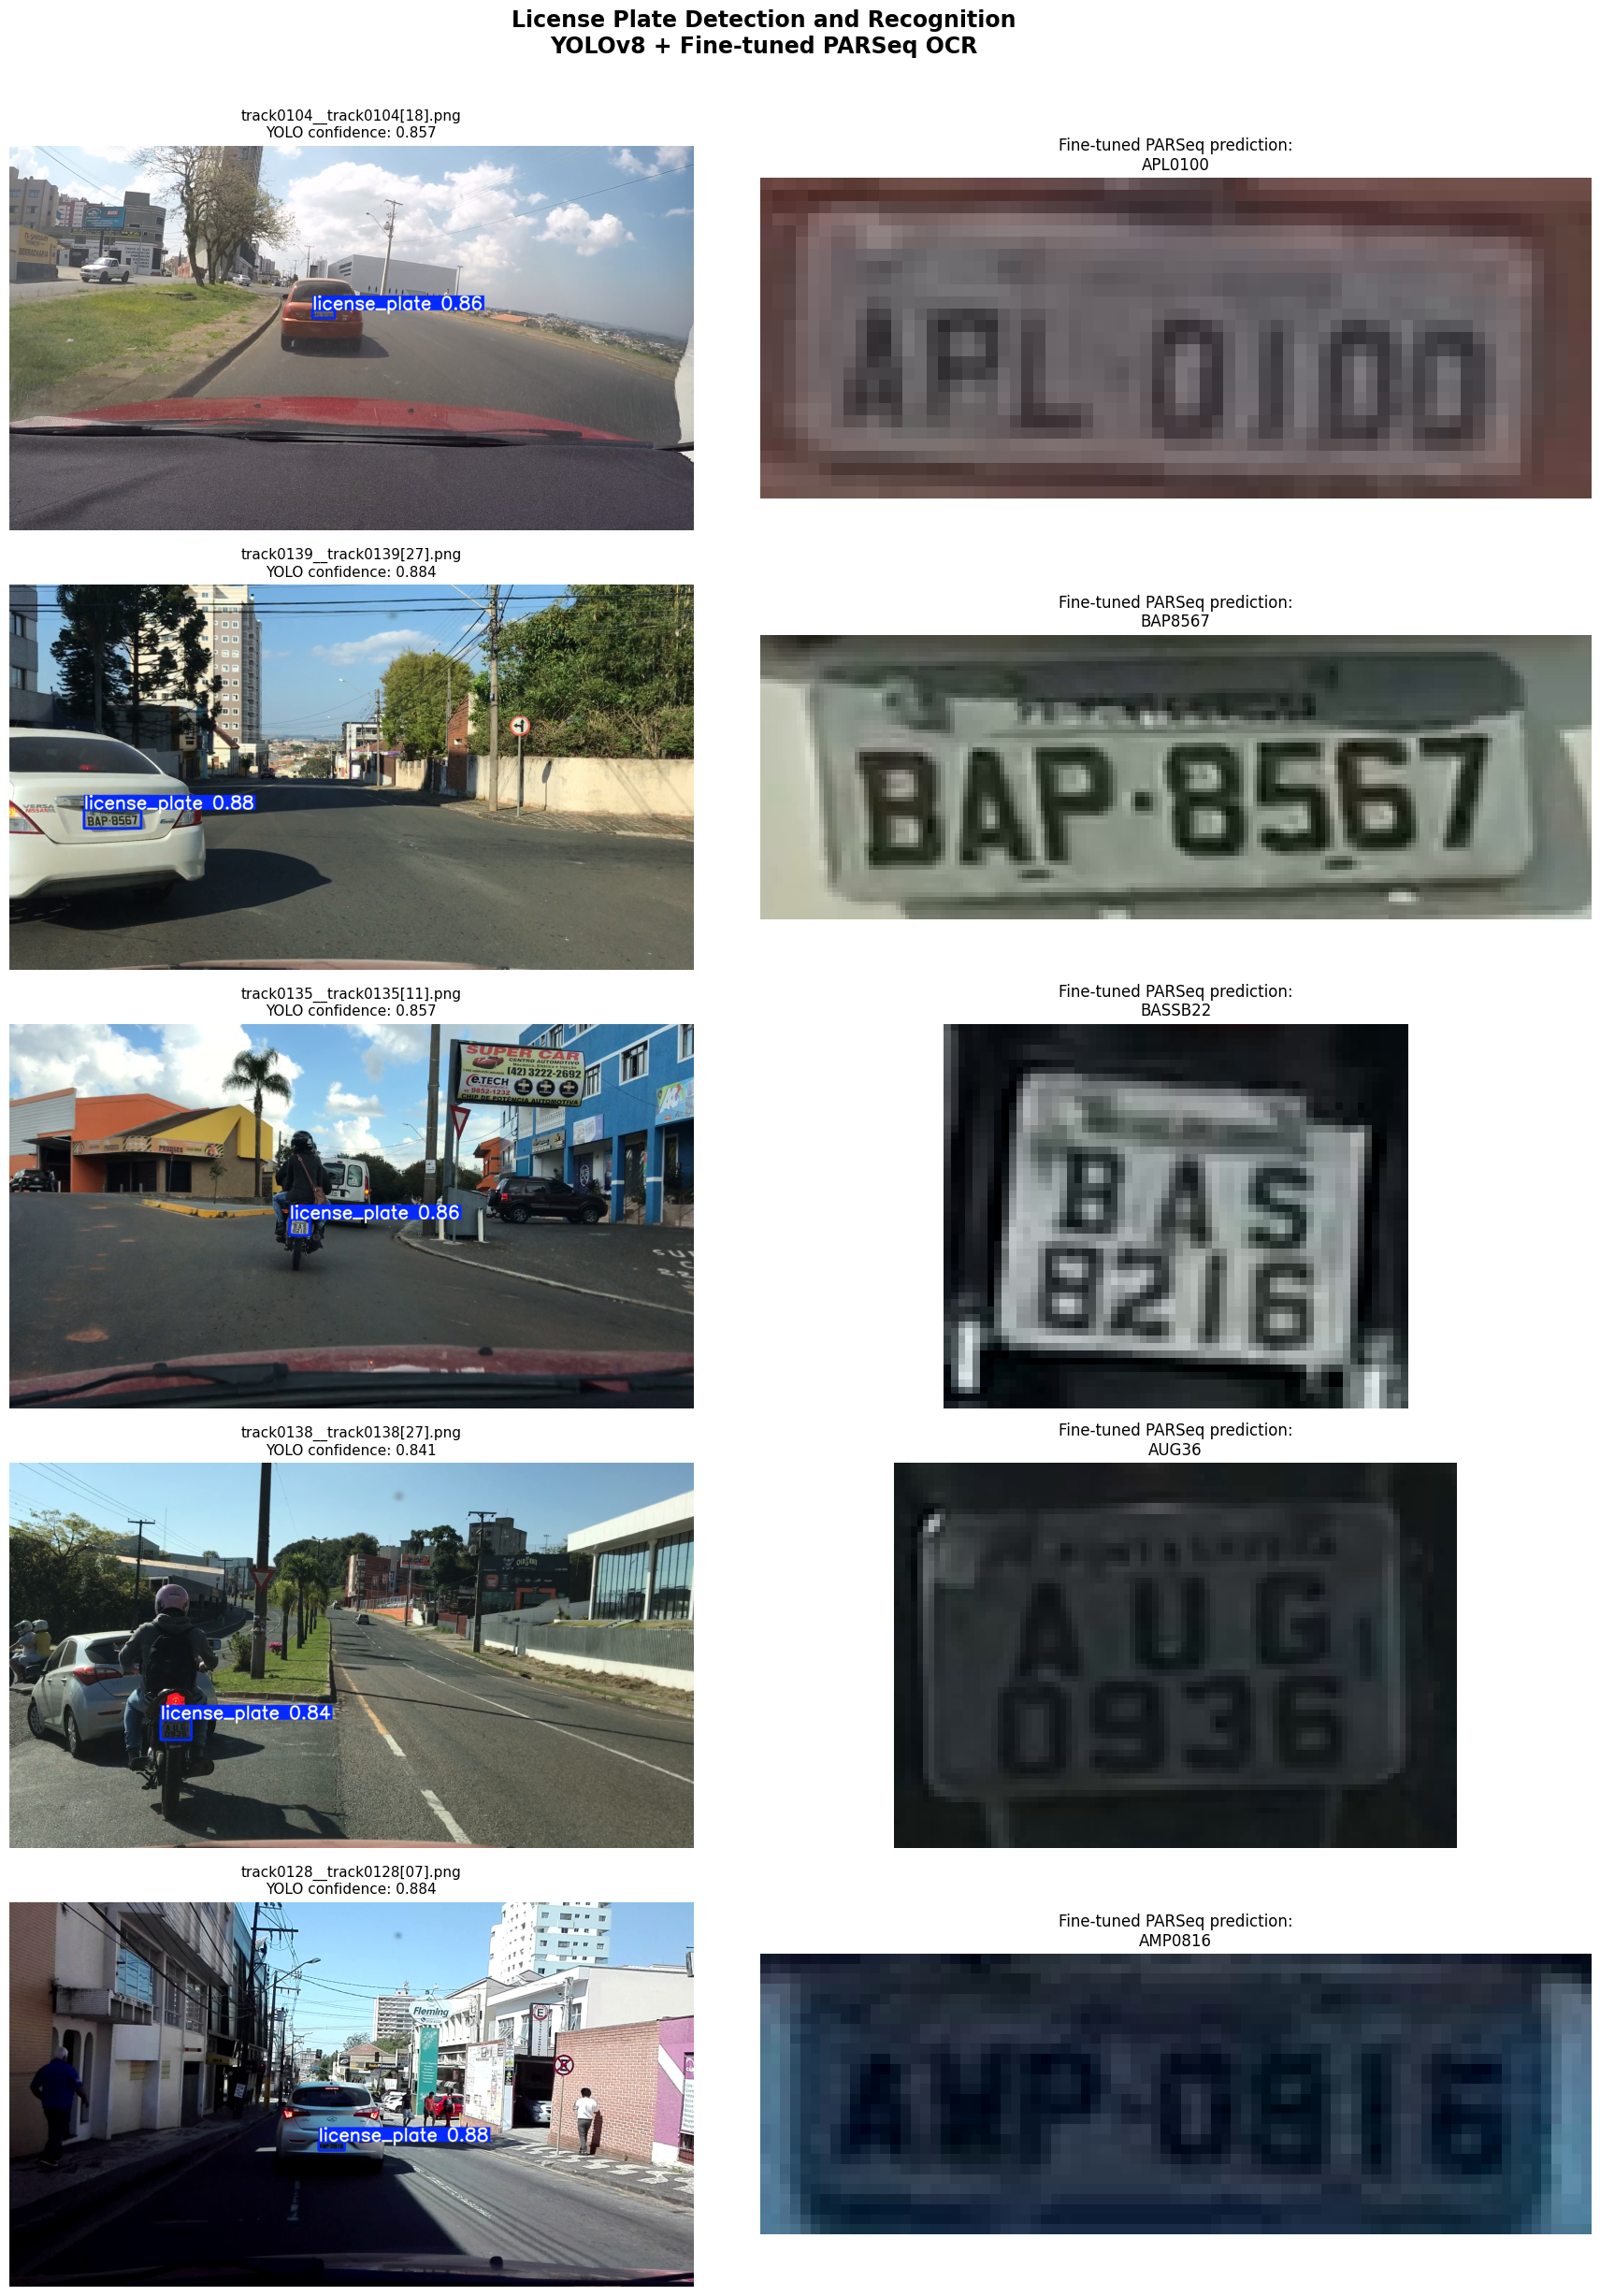


PREDICTIONS
track0104__track0104[18].png | PARSeq: APL0100 | YOLO confidence: 0.857
track0139__track0139[27].png | PARSeq: BAP8567 | YOLO confidence: 0.884
track0135__track0135[11].png | PARSeq: BASSB22 | YOLO confidence: 0.857
track0138__track0138[27].png | PARSeq: AUG36 | YOLO confidence: 0.841
track0128__track0128[07].png | PARSeq: AMP0816 | YOLO confidence: 0.884

INFERENCE TIMING
YOLO batch: 0.028 seconds
PARSeq batch: 0.265 seconds
Average model inference: 0.059 seconds/image
(Excludes image loading and visualization.)

Saved results: /content/drive/MyDrive/UFPR_ALPR_Project/evaluation_report/parseq_random_5_image_demo.json


In [23]:

# ============================================================
# FINAL FAST DEMO: YOLOv8 + FINE-TUNED PARSeq OCR
# 5 RANDOM TEST IMAGES | Google Colab Tesla T4
# Larger detection resolution + large display
# ============================================================

import os
import glob
import json
import random
import time
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
PROJECT = "/content/drive/MyDrive/UFPR_ALPR_Project"
TEST_DIR = f"{PROJECT}/yolo_dataset/images/test"
REPORT_DIR = f"{PROJECT}/evaluation_report"

NUM_IMAGES = 5
YOLO_IMGSZ = 640       # Higher detection resolution
YOLO_CONF = 0.25

os.makedirs(REPORT_DIR, exist_ok=True)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

# ------------------------------------------------------------
# 2. Select five random images (new selection every run)
# ------------------------------------------------------------
image_paths = []

for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp"):
    image_paths.extend(glob.glob(os.path.join(TEST_DIR, ext)))

image_paths = sorted(set(image_paths))

if not image_paths:
    raise FileNotFoundError(f"No images found in {TEST_DIR}")

samples = random.sample(
    image_paths,
    min(NUM_IMAGES, len(image_paths))
)

images, valid_paths = [], []

for path in samples:
    img = cv2.imread(path)
    if img is not None:
        images.append(img)
        valid_paths.append(path)

if not images:
    raise RuntimeError("Unable to read selected images.")

print(f"Selected {len(images)} random images:")
for path in valid_paths:
    print(" -", os.path.basename(path))

print("Device:", device)

# ------------------------------------------------------------
# 3. Batch YOLOv8 detection
# ------------------------------------------------------------
if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.inference_mode():
    results = detector.predict(
        source=images,
        imgsz=YOLO_IMGSZ,
        conf=YOLO_CONF,
        batch=len(images),
        device=0 if torch.cuda.is_available() else "cpu",
        half=torch.cuda.is_available(),
        max_det=5,
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

yolo_seconds = time.perf_counter() - start

# ------------------------------------------------------------
# 4. Crop the highest-confidence plate in each image
# ------------------------------------------------------------
crops, crop_indices = [], []
confidences = [0.0] * len(images)
predictions = ["Plate not detected"] * len(images)

for i, (img, result) in enumerate(zip(images, results)):
    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        continue

    best_idx = int(boxes.conf.argmax().item())

    x1, y1, x2, y2 = map(
        int, boxes.xyxy[best_idx].tolist()
    )
    confidences[i] = float(boxes.conf[best_idx].item())

    h, w = img.shape[:2]
    pad_x = int((x2 - x1) * 0.08)
    pad_y = int((y2 - y1) * 0.10)

    x1, y1 = max(0, x1 - pad_x), max(0, y1 - pad_y)
    x2, y2 = min(w, x2 + pad_x), min(h, y2 + pad_y)

    if x2 <= x1 or y2 <= y1:
        continue

    crop_rgb = cv2.cvtColor(
        img[y1:y2, x1:x2],
        cv2.COLOR_BGR2RGB
    )

    crops.append(Image.fromarray(crop_rgb))
    crop_indices.append(i)

# ------------------------------------------------------------
# 5. Batch PARSeq OCR
# ------------------------------------------------------------
ocr_seconds = 0.0

if crops:
    # Preprocess every crop, then infer in one batch
    tensors = torch.stack([
        parseq_transform(crop) for crop in crops
    ]).to(device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        # Use FP16 for PARSeq on CUDA; convert output back to FP32
        if torch.cuda.is_available():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = parseq_model(tensors)
        else:
            logits = parseq_model(tensors)

        probabilities = logits.float().softmax(dim=-1)
        decoded = parseq_model.tokenizer.decode(probabilities)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    ocr_seconds = time.perf_counter() - start

    labels, _ = decoded

    for idx, label in zip(crop_indices, labels):
        predictions[idx] = str(label).strip().upper()

# ------------------------------------------------------------
# 6. Display large detection and OCR results
# ------------------------------------------------------------
fig, axes = plt.subplots(
    len(images),
    2,
    figsize=(18, 5 * len(images)),
    dpi=100
)

if len(images) == 1:
    axes = np.array([axes])

records = []

for i, (img, result, path) in enumerate(
    zip(images, results, valid_paths)
):
    # Draw detection boxes
    annotated = result.plot()

    axes[i, 0].imshow(
        cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(
        f"{os.path.basename(path)}\n"
        f"YOLO confidence: {confidences[i]:.3f}",
        fontsize=11
    )
    axes[i, 0].axis("off")

    # Display plate crop
    if i in crop_indices:
        crop_pos = crop_indices.index(i)
        axes[i, 1].imshow(crops[crop_pos])
    else:
        axes[i, 1].text(
            0.5, 0.5, "No license plate detected",
            ha="center", va="center",
            fontsize=12,
            transform=axes[i, 1].transAxes
        )

    axes[i, 1].set_title(
        f"Fine-tuned PARSeq prediction:\n{predictions[i]}",
        fontsize=12
    )
    axes[i, 1].axis("off")

    records.append({
        "image": os.path.basename(path),
        "predicted_plate": predictions[i],
        "detection_confidence": round(confidences[i], 4)
    })

plt.suptitle(
    "License Plate Detection and Recognition\n"
    "YOLOv8 + Fine-tuned PARSeq OCR",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Save results and report timing
# ------------------------------------------------------------
report_path = os.path.join(
    REPORT_DIR,
    "parseq_random_5_image_demo.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("\nPREDICTIONS")
print("=" * 70)

for record in records:
    print(
        f"{record['image']} | "
        f"PARSeq: {record['predicted_plate']} | "
        f"YOLO confidence: {record['detection_confidence']:.3f}"
    )

total_seconds = yolo_seconds + ocr_seconds

print("\nINFERENCE TIMING")
print(f"YOLO batch: {yolo_seconds:.3f} seconds")
print(f"PARSeq batch: {ocr_seconds:.3f} seconds")
print(
    f"Average model inference: "
    f"{total_seconds / len(images):.3f} seconds/image"
)
print("(Excludes image loading and visualization.)")
print("\nSaved results:", report_path)


In [ ]:

# FINAL CELL: Complete YOLOv8 Test Evaluation for DL Report
# Runs test evaluation once. Does not retrain the model.

import os
import glob
import json
import time
import csv
import numpy as np
import torch
from ultralytics import YOLO
from IPython.display import display, HTML

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------
PROJECT = "/content/drive/MyDrive/UFPR_ALPR_Project"
MODEL_PATH = f"{PROJECT}/checkpoints/yolov8_plate_detect/weights/best.pt"
DATA_YAML = f"{PROJECT}/dataset_config/dataset.yaml"
TEST_IMAGES = f"{PROJECT}/yolo_dataset/images/test"
TEST_LABELS = f"{PROJECT}/yolo_dataset/labels/test"

REPORT_DIR = f"{PROJECT}/evaluation_report"
os.makedirs(REPORT_DIR, exist_ok=True)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not os.path.exists(DATA_YAML):
    raise FileNotFoundError(f"Dataset configuration not found: {DATA_YAML}")

# Automatically select GPU if available
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Evaluation device:", "GPU" if DEVICE == 0 else "CPU")

model = YOLO(MODEL_PATH)

# --------------------------------------------------
# 2. Official Ultralytics test metrics
# --------------------------------------------------
print("\nEvaluating the complete test split. Please wait...")

val_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    plots=False,
    verbose=False
)

box_metrics = val_results.box

report = {
    "Model": "YOLOv8n",
    "Evaluation split": "Test",
    "Test images": len(
        glob.glob(os.path.join(TEST_IMAGES, "*.png"))
        + glob.glob(os.path.join(TEST_IMAGES, "*.jpg"))
        + glob.glob(os.path.join(TEST_IMAGES, "*.jpeg"))
    ),
    "Precision": float(box_metrics.mp),
    "Recall": float(box_metrics.mr),
    "mAP@50": float(box_metrics.map50),
    "mAP@50-95": float(box_metrics.map),
}

# F1 derived from overall precision and recall
p = report["Precision"]
r = report["Recall"]
report["F1 score"] = (
    2 * p * r / (p + r) if (p + r) > 0 else 0.0
)

# Inference timing reported by Ultralytics, usually ms per image
speed = getattr(val_results, "speed", {})
report["Preprocess time (ms/image)"] = float(speed.get("preprocess", 0))
report["Inference time (ms/image)"] = float(speed.get("inference", 0))
report["Postprocess time (ms/image)"] = float(speed.get("postprocess", 0))

# --------------------------------------------------
# 3. Calculate IoU and Dice for matched bounding boxes
#    using the saved YOLO test labels
# --------------------------------------------------
def box_iou_xyxy(box_a, box_b):
    """IoU between two boxes in pixel coordinates."""
    ix1 = max(box_a[0], box_b[0])
    iy1 = max(box_a[1], box_b[1])
    ix2 = min(box_a[2], box_b[2])
    iy2 = min(box_a[3], box_b[3])

    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)

    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def load_gt_boxes(label_path, width, height):
    """Read YOLO labels: class x_center y_center width height."""
    boxes = []

    if not os.path.exists(label_path):
        return boxes

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            values = line.strip().split()
            if len(values) < 5:
                continue

            _, xc, yc, bw, bh = map(float, values[:5])

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            boxes.append([x1, y1, x2, y2])

    return boxes


image_paths = []
for ext in ("*.png", "*.jpg", "*.jpeg"):
    image_paths.extend(glob.glob(os.path.join(TEST_IMAGES, ext)))

if not image_paths:
    raise FileNotFoundError(f"No test images found in {TEST_IMAGES}")

tp = fp = fn = 0
matched_ious = []
total_inference_seconds = 0.0
images_processed = 0

# Use one-to-one greedy matching at IoU >= 0.50
IOU_THRESHOLD = 0.50

for image_path in image_paths:
    import cv2

    image = cv2.imread(image_path)
    if image is None:
        continue

    height, width = image.shape[:2]
    label_path = os.path.join(
        TEST_LABELS,
        os.path.splitext(os.path.basename(image_path))[0] + ".txt"
    )
    gt_boxes = load_gt_boxes(label_path, width, height)

    start = time.perf_counter()
    result = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]
    total_inference_seconds += time.perf_counter() - start
    images_processed += 1

    pred_boxes = []
    if result.boxes is not None and len(result.boxes) > 0:
        pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()

    # Build all candidate pairs, highest IoU first
    pairs = []
    for gi, gt in enumerate(gt_boxes):
        for pi, pred in enumerate(pred_boxes):
            overlap = box_iou_xyxy(gt, pred)
            if overlap >= IOU_THRESHOLD:
                pairs.append((overlap, gi, pi))

    pairs.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()

    for overlap, gi, pi in pairs:
        if gi not in matched_gt and pi not in matched_pred:
            matched_gt.add(gi)
            matched_pred.add(pi)
            matched_ious.append(overlap)

    tp += len(matched_gt)
    fp += len(pred_boxes) - len(matched_pred)
    fn += len(gt_boxes) - len(matched_gt)

# Detection metrics based on the above one-to-one matching
manual_precision = tp / (tp + fp) if tp + fp else 0.0
manual_recall = tp / (tp + fn) if tp + fn else 0.0

report["F1 at IoU 0.50"] = (
    2 * manual_precision * manual_recall /
    (manual_precision + manual_recall)
    if manual_precision + manual_recall else 0.0
)
report["Matched true positives at IoU 0.50"] = int(tp)
report["False positives at IoU 0.50"] = int(fp)
report["False negatives at IoU 0.50"] = int(fn)
report["Manual precision at IoU 0.50"] = manual_precision
report["Manual recall at IoU 0.50"] = manual_recall
report["Mean IoU of matched boxes"] = (
    float(np.mean(matched_ious)) if matched_ious else 0.0
)

# Dice is calculated from matched bounding-box overlap:
# Dice = 2 * IoU / (1 + IoU)
report["Mean Dice of matched boxes"] = (
    float(np.mean([2 * i / (1 + i) for i in matched_ious]))
    if matched_ious else 0.0
)

report["Custom inference time (ms/image)"] = (
    1000 * total_inference_seconds / images_processed
    if images_processed else 0.0
)
report["IoU matching threshold"] = IOU_THRESHOLD

# --------------------------------------------------
# 4. Save results for the report
# --------------------------------------------------
json_path = os.path.join(REPORT_DIR, "yolov8_test_metrics.json")
csv_path = os.path.join(REPORT_DIR, "yolov8_test_metrics.csv")

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=4)

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Metric", "Value"])
    writer.writerows(report.items())

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------
print("\n========== YOLOv8 TEST EVALUATION ==========")

for key, value in report.items():
    if isinstance(value, float):
        print(f"{key:<40}: {value:.4f}")
    else:
        print(f"{key:<40}: {value}")

print("\nSaved report files:")
print(json_path)
print(csv_path)

display(HTML(f"""
<div style="font-family:Arial;padding:20px;border:1px solid #d1d5db;
border-radius:14px;max-width:850px">
<h2>YOLOv8n — Test Evaluation Complete</h2>
<p>Images processed: <b>{images_processed}</b></p>
<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px">
{''.join(
    f'<div style="padding:14px;background:#f1f5f9;border-radius:10px">'
    f'<div style="font-size:13px;color:#475569">{name}</div>'
    f'<div style="font-size:25px;font-weight:700;color:#0f172a">{value:.4f}</div>'
    f'</div>'
    for name, value in [
        ("Precision", report["Precision"]),
        ("Recall", report["Recall"]),
        ("mAP @ 50", report["mAP@50"]),
        ("mAP @ 50–95", report["mAP@50-95"]),
        ("F1 @ IoU 0.50", report["F1 at IoU 0.50"]),
        ("Mean matched-box IoU", report["Mean IoU of matched boxes"]),
        ("Mean matched-box Dice", report["Mean Dice of matched boxes"]),
        ("Inference ms/image", report["Custom inference time (ms/image)"])
    ]
)}
</div>
<p style="font-size:12px;color:#64748b;margin-top:16px">
IoU and Dice are computed only for matched bounding boxes at IoU ≥ 0.50.
They are not segmentation-mask metrics. Standard object-detection accuracy
is not a single universally defined metric, so precision, recall, F1 and mAP
are reported instead.
</p>
</div>
"""))


Evaluation device: GPU

Evaluating the complete test split. Please wait...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 618.3±153.6 MB/s, size: 2194.7 KB)
val: Scanning /content/drive/MyDrive/UFPR_ALPR_Project/yolo_dataset/labels/test.cache... 1800 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1800/1800 279.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 225/225 10.1it/s 22.3s
                   all       1800       1800       0.96       0.96      0.985      0.721
Speed: 0.6ms preprocess, 2.9ms inference, 0.0ms loss, 1.1ms postprocess per image

========== YOLOv8 TEST EVALUATION ==========
Model                                   : YOLOv8n
Evaluation split                        : Test
Test images                             : 1800
Precision   

In [27]:
import os, glob, time, torch, cv2
from PIL import Image

PROJECT = "/content/drive/MyDrive/UFPR_ALPR_Project"
IMG_DIR = f"{PROJECT}/yolo_dataset/images/test"
LABEL_DIR = f"{PROJECT}/yolo_dataset/labels/test"
REPORT_DIR = f"{PROJECT}/parseq_ocr"
os.makedirs(REPORT_DIR, exist_ok=True)

MAX_IMAGES = 200  # Increase to None for the full test set
BATCH_SIZE = 32 if torch.cuda.is_available() else 8

def read_boxes(path, w, h):
    boxes = []
    if os.path.exists(path):
        for line in open(path):
            v = line.split()
            if len(v) >= 5:
                _, x, y, bw, bh = map(float, v[:5])
                boxes.append((
                    max(0, int((x-bw/2)*w)), max(0, int((y-bh/2)*h)),
                    min(w, int((x+bw/2)*w)), min(h, int((y+bh/2)*h))
                ))
    return boxes

images = sorted(
    p for ext in ("*.png", "*.jpg", "*.jpeg")
    for p in glob.glob(os.path.join(IMG_DIR, ext))
)
if MAX_IMAGES:
    images = images[:MAX_IMAGES]

# Map original annotation files
ann = {}
for split in ("training", "validation", "testing"):
    for p in glob.glob(
        f"/content/drive/MyDrive/UFPR-ALPR dataset/{split}/**/*.txt",
        recursive=True
    ):
        ann[os.path.splitext(os.path.basename(p))[0]] = p

def get_gt(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    for key in (stem, stem.split("__", 1)[-1]):
        if key in ann:
            for line in open(ann[key], encoding="utf-8"):
                if line.lower().startswith("plate:"):
                    return "".join(c for c in line.split(":",1)[1].upper()
                                   if c.isalnum())
    return None

parseq_model.eval().to(device)
correct = total = exact = evaluated = skipped = 0
start = time.time()
tensors, truths = [], []

def evaluate_batch():
    global correct, total, exact, evaluated
    if not tensors:
        return
    batch = torch.stack(tensors).to(device)
    with torch.inference_mode():
        logits = parseq_model(batch)
        probs = logits.float().softmax(-1)
        decoded = parseq_model.tokenizer.decode(probs)
    predictions, _ = decoded

    for pred, gt in zip(predictions, truths):
        pred = "".join(c for c in pred.upper() if c.isalnum())
        d = [[0]*(len(pred)+1) for _ in range(len(gt)+1)]
        for i in range(len(gt)+1): d[i][0] = i
        for j in range(len(pred)+1): d[0][j] = j
        for i in range(1,len(gt)+1):
            for j in range(1,len(pred)+1):
                d[i][j] = min(d[i-1][j]+1, d[i][j-1]+1,
                              d[i-1][j-1]+(gt[i-1] != pred[j-1]))
        dist = d[-1][-1]
        exact += (gt == pred)
        correct += max(0, len(gt)-dist)
        total += len(gt)
        evaluated += 1
    tensors.clear()
    truths.clear()

for path in images:
    image = cv2.imread(path)
    gt = get_gt(path)
    if image is None or not gt:
        skipped += 1
        continue
    h, w = image.shape[:2]
    label = os.path.join(LABEL_DIR, os.path.splitext(os.path.basename(path))[0]+".txt")
    boxes = read_boxes(label, w, h)
    if not boxes:
        skipped += 1
        continue
    x1,y1,x2,y2 = boxes[0]
    crop = image[y1:y2, x1:x2]
    if crop.size == 0:
        skipped += 1
        continue
    crop = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    tensors.append(parseq_transform(crop))
    truths.append(gt)
    if len(tensors) >= BATCH_SIZE:
        evaluate_batch()

evaluate_batch()

report = {
    "Images selected": len(images),
    "Samples evaluated": evaluated,
    "Samples skipped": skipped,
    "Exact match accuracy (%)": round(100*exact/evaluated, 2) if evaluated else 0,
    "Character accuracy (%)": round(100*correct/total, 2) if total else 0,
    "Elapsed seconds": round(time.time()-start, 2),
    "Device": str(device)
}

import json
with open(f"{REPORT_DIR}/parseq_quick_test.json", "w") as f:
    json.dump(report, f, indent=2)

from IPython.display import display, HTML
import json

with open(f"{REPORT_DIR}/parseq_quick_test.json", "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 58)
print("       PARSeq OCR — TEST EVALUATION REPORT")
print("=" * 58)
print(f"{'Model':<30}: Fine-tuned PARSeq")
print(f"{'Evaluation device':<30}: {report['Device']}")
print("-" * 58)
print(f"{'Images selected':<30}: {report['Images selected']}")
print(f"{'Samples evaluated':<30}: {report['Samples evaluated']}")
print(f"{'Samples skipped':<30}: {report['Samples skipped']}")
print("-" * 58)
print(f"{'Exact-match accuracy':<30}: {report['Exact match accuracy (%)']:.2f}%")
print(f"{'Character accuracy':<30}: {report['Character accuracy (%)']:.2f}%")
print(f"{'Total evaluation time':<30}: {report['Elapsed seconds']:.2f} seconds")

if report["Samples evaluated"]:
    print(f"{'Average time per image':<30}: "
          f"{report['Elapsed seconds'] / report['Samples evaluated']:.4f} seconds")

print("=" * 58)
print(f"Report saved to: {REPORT_DIR}/parseq_quick_test.json")




       PARSeq OCR — TEST EVALUATION REPORT
Model                         : Fine-tuned PARSeq
Evaluation device             : cuda
----------------------------------------------------------
Images selected               : 200
Samples evaluated             : 200
Samples skipped               : 0
----------------------------------------------------------
Exact-match accuracy          : 96.00%
Character accuracy            : 98.86%
Total evaluation time         : 11.83 seconds
Average time per image        : 0.0592 seconds
Report saved to: /content/drive/MyDrive/UFPR_ALPR_Project/parseq_ocr/parseq_quick_test.json
